# NYC Taxi Data - Customer Segmentation (K-Means Clustering)
This notebook implements the K-Means clustering pipeline to segment NYC Taxi customers based on their trip behavior (Distance, Fare, Tip).


In [3]:
import os
os.environ["JAVA_HOME"] = r"d:\School\spark\NYC_Taxi_Data_Pipeline-main\jdk\jdk-17.0.10+7"

import sys
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Config logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s:%(levelname)s:%(message)s')


### 1. Khởi tạo Spark Session

In [4]:
spark = SparkSession.builder \
    .appName("Customer Segmentation ML (Jupyter)") \
    .getOrCreate()
print("Spark Session created successfully!")


Spark Session created successfully!


### 2. Đọc dữ liệu
Đọc file dữ liệu Parquet từ máy cục bộ.

In [5]:
# Path to local parquet file
data_path = "../../data/2022/yellow_tripdata_2022-01.parquet"

try:
    df = spark.read.parquet(data_path)
    print(f"Data loaded successfully! Total records: {df.count()}")
except Exception as e:
    print("Error loading data. Make sure the data file exists in data/2022/ folder.")
    print(e)


Data loaded successfully! Total records: 2463931


### 3. Tiền xử lý dữ liệu & Lọc nhiễu (Outliers)
Lọc bỏ các cuốc xe có quãng đường quá lớn hoặc tiền cước vô lý để không làm hỏng mô hình. Lấy mẫu 10% dữ liệu để training nhanh.

In [6]:
# ĐÃ SỬA LỖI OUTLIERS: Ép trip_distance < 50 để biểu đồ hội tụ đẹp hơn
clean_df = df.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 50) & 
    (col("fare_amount") > 0) & (col("fare_amount") < 500)
).dropna(subset=["trip_distance", "fare_amount", "tip_amount"])

# Lấy mẫu 10%
sample_df = clean_df.sample(withReplacement=False, fraction=0.1, seed=42)
print(f"Training dataset size: {sample_df.count()}")


Training dataset size: 242663


### 3.5. Exploratory Data Analysis: Correlation Heatmap
Vẽ ma trận tương quan giữa 3 thuộc tính (Quãng đường, Cước, Tip) để xem chúng có bị đa cộng tuyến (hoàn toàn phụ thuộc vào nhau) hay không.

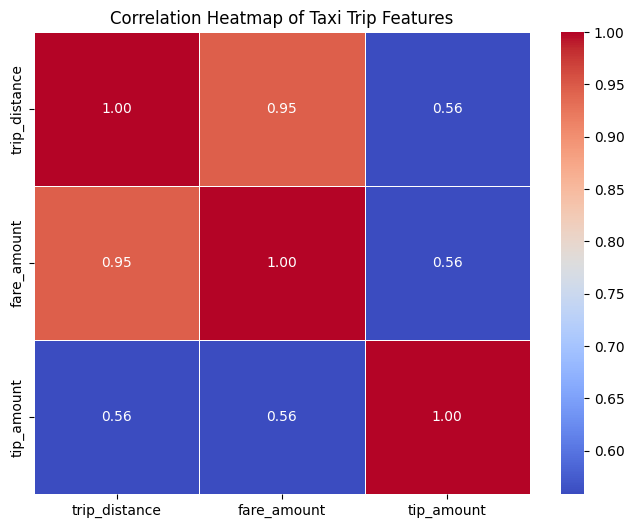

-> Phân tích: fare_amount và trip_distance có độ tương quan rất cao (như kỳ vọng).
-> Tuy nhiên, tip_amount lại không hoàn toàn tương quan tuyến tính chặt chẽ với cước/quãng đường.
-> Điều này chính là lý do K-Means có thể tìm ra được các cụm khách hàng đi xa nhưng tip ít, hoặc ngược lại!


In [7]:
# Convert a small sample to Pandas DataFrame for visualization
pdf = sample_df.select("trip_distance", "fare_amount", "tip_amount").toPandas()

plt.figure(figsize=(8, 6))
correlation_matrix = pdf.corr()

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Taxi Trip Features")
plt.show()

print("-> Phân tích: fare_amount và trip_distance có độ tương quan rất cao (như kỳ vọng).")
print("-> Tuy nhiên, tip_amount lại không hoàn toàn tương quan tuyến tính chặt chẽ với cước/quãng đường.")
print("-> Điều này chính là lý do K-Means có thể tìm ra được các cụm khách hàng đi xa nhưng tip ít, hoặc ngược lại!")


### 4. Chuẩn bị Features (VectorAssembler & StandardScaler)
K-Means rất nhạy cảm với thang đo của dữ liệu. Chúng ta phải gom cột và dùng StandardScaler để cân bằng (scale) dữ liệu.

In [8]:
# Gom cột
features_cols = ["trip_distance", "fare_amount", "tip_amount"]
assembler = VectorAssembler(inputCols=features_cols, outputCol="raw_features")
assembled_data = assembler.transform(sample_df)

# Chuẩn hóa
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(assembled_data)
scaled_data = scaler_model.transform(assembled_data)

scaled_data.select("features").show(5, truncate=False)


+----------------------------------------------------------------+
|features                                                        |
+----------------------------------------------------------------+
|[0.16266551893221978,0.1527785379814685,0.4707288335508056]     |
|[-0.2607826081492005,-0.4141271359399967,0.6025915157211845]    |
|[-0.10883945666704382,-0.06526210583447965,-0.05672189513071024]|
|[1.6322796070383259,1.8971036885090538,2.569229232662265]       |
|[-0.567159782449287,-0.6321677797559448,-0.03034935869663451]   |
+----------------------------------------------------------------+
only showing top 5 rows


### 4.5. Chọn số cụm tối ưu (Elbow Method chuẩn WSSSE)
Trước khi chia nhóm, chúng ta sẽ tính tổng bình phương khoảng cách nội cụm (WSSSE) với k từ 2 đến 7. Biểu đồ sẽ tạo ra hình dáng 'Khuỷu tay', điểm uốn chính là k tốt nhất.

Đang chạy tính toán Elbow Method (Có thể mất 1-2 phút)...
k=2 | WSSSE (Cost): 316,885
k=3 | WSSSE (Cost): 238,432
k=4 | WSSSE (Cost): 193,386
k=5 | WSSSE (Cost): 171,277
k=6 | WSSSE (Cost): 128,383
k=7 | WSSSE (Cost): 109,915


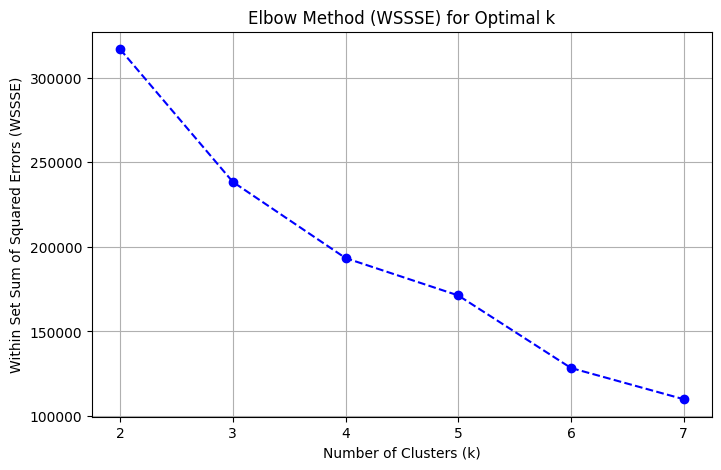

-> Nhận xét: Nhìn vào biểu đồ, điểm uốn (Elbow) gập mạnh nhất nằm ở khoảng k=3 hoặc k=4.
-> Dựa vào mục tiêu kinh doanh muốn chia khách hàng chi tiết hơn, chúng ta sẽ chọn k=4 làm số cụm chính thức ở bước tiếp theo!


In [9]:
wssse_scores = []
k_values = range(2, 8)

print("Đang chạy tính toán Elbow Method (Có thể mất 1-2 phút)...")
for k_val in k_values:
    kmeans_temp = KMeans(featuresCol="features", predictionCol="cluster", k=k_val, seed=1)
    model_temp = kmeans_temp.fit(scaled_data)
    
    # Lấy chỉ số WSSSE (Cost) chuẩn của thuật toán K-Means
    cost = model_temp.summary.trainingCost
    wssse_scores.append(cost)
    print(f"k={k_val} | WSSSE (Cost): {cost:,.0f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, wssse_scores, marker='o', linestyle='--', color='b')
plt.title("Elbow Method (WSSSE) for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within Set Sum of Squared Errors (WSSSE)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

print("-> Nhận xét: Nhìn vào biểu đồ, điểm uốn (Elbow) gập mạnh nhất nằm ở khoảng k=3 hoặc k=4.")
print("-> Dựa vào mục tiêu kinh doanh muốn chia khách hàng chi tiết hơn, chúng ta sẽ chọn k=4 làm số cụm chính thức ở bước tiếp theo!")


### 5. Đào tạo mô hình K-Means và Chia nhóm khách hàng
Sau khi đã xác định được k=4 từ biểu đồ Elbow, tiến hành phân cụm dữ liệu.

In [10]:
k = 4 # Đã được chọn từ Elbow Method ở trên
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=1)
model = kmeans.fit(scaled_data)

predictions = model.transform(scaled_data)
print("Đã hoàn tất chia nhóm khách hàng!")


Đã hoàn tất chia nhóm khách hàng!


### 6. Đánh giá Mô hình và Phân tích Cụm

In [11]:
evaluator = ClusteringEvaluator(predictionCol="cluster", featuresCol="features")
silhouette = evaluator.evaluate(predictions)
print(f"Silhouette Score (Chỉ số đánh giá độ tách biệt các cụm): {silhouette:.4f}\n")

print("--- ĐẶC ĐIỂM CÁC PHÂN KHÚC KHÁCH HÀNG (Tâm Cụm Đã Scale) ---")
centers = model.clusterCenters()
for i, center in enumerate(centers):
    print(f"Cụm {i}: Distance: {center[0]:.2f} | Fare: {center[1]:.2f} | Tip: {center[2]:.2f}")


Silhouette Score (Chỉ số đánh giá độ tách biệt các cụm): 0.6075

--- ĐẶC ĐIỂM CÁC PHÂN KHÚC KHÁCH HÀNG (Tâm Cụm Đã Scale) ---
Cụm 0: Distance: -0.42 | Fare: -0.44 | Tip: -0.37
Cụm 1: Distance: 3.63 | Fare: 3.52 | Tip: 3.79
Cụm 2: Distance: 2.19 | Fare: 2.14 | Tip: 0.56
Cụm 3: Distance: 0.17 | Fare: 0.24 | Tip: 0.43


### 7. Trực quan hóa kết quả Phân cụm (Visualizations)
Vẽ biểu đồ phân tán (Scatter Plot) và biểu đồ đếm (Bar Chart) để nhìn rõ bức tranh kinh doanh.

2026-08-09 23:30:00,681:INFO:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-09 23:30:00,970:INFO:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


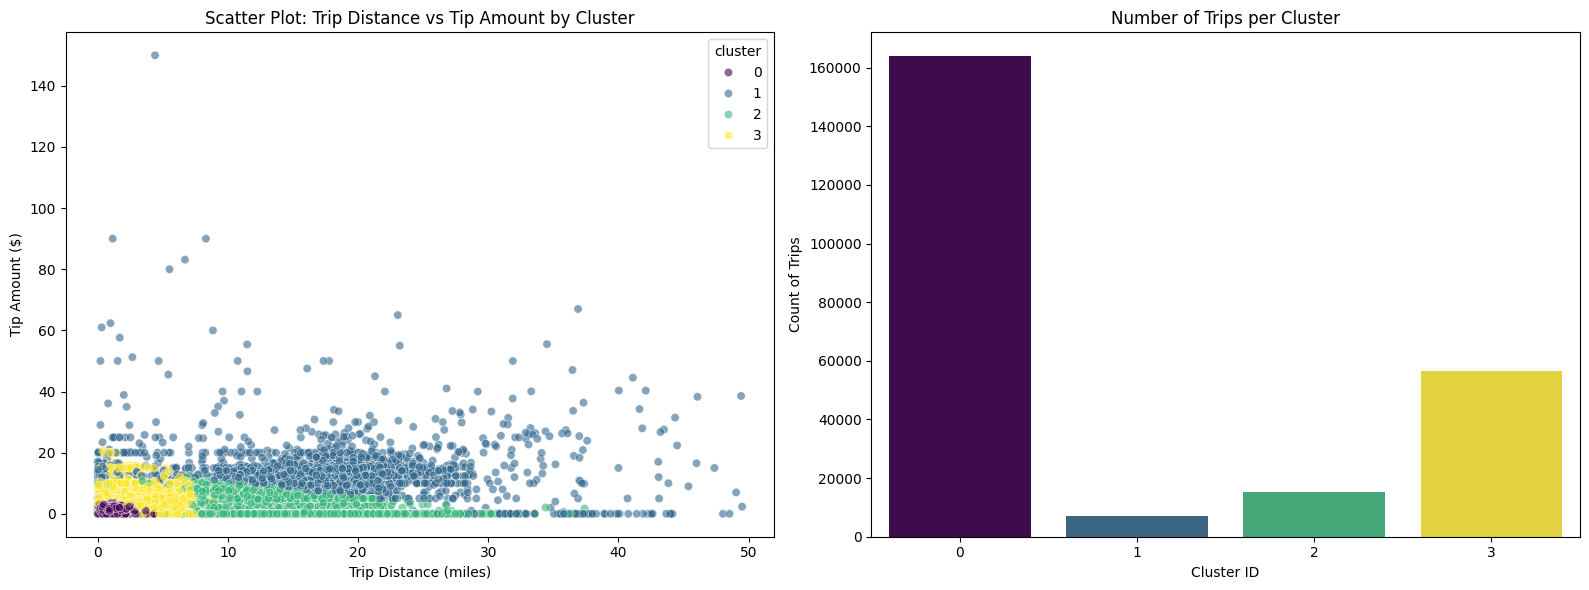

In [12]:
# Chuyển kết quả dự đoán (sample) sang Pandas để vẽ
preds_pdf = predictions.select("trip_distance", "fare_amount", "tip_amount", "cluster").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatter Plot
sns.scatterplot(
    data=preds_pdf, 
    x="trip_distance", 
    y="tip_amount", 
    hue="cluster", 
    palette="viridis", 
    alpha=0.6,
    ax=ax[0]
)
ax[0].set_title("Scatter Plot: Trip Distance vs Tip Amount by Cluster")
ax[0].set_xlabel("Trip Distance (miles)")
ax[0].set_ylabel("Tip Amount ($)")

# 2. Bar Chart Count
# ĐÃ SỬA LỖI FUTURE WARNING CỦA SEABORN
sns.countplot(
    data=preds_pdf, 
    x="cluster", 
    palette="viridis", 
    hue="cluster", 
    legend=False,
    ax=ax[1]
)
ax[1].set_title("Number of Trips per Cluster")
ax[1].set_xlabel("Cluster ID")
ax[1].set_ylabel("Count of Trips")

plt.tight_layout()
plt.show()
